# Does one more bidder lower the price? Competition in Portuguese public tenders

**Question.** In open tenders and prior consultations, how much lower is the signed price, relative to the
procedure's base price, when more companies bid? And how often does a tender get only one bid?

**Data.** 1.55 million public contracts published on Portal BASE (IMPIC), January 2019 to 24 October 2026,
the same raw files the [dbt project](../models) uses. This notebook works from the raw Parquet files in pandas,
independently of the SQL models, and checks that both give the same totals.

**Short answer** (the numbers are computed below):

* With a single bid, open tenders sign at a median **99.3%** of the base price. With ten or more bids, at **79.4%**.
* After controlling for category, year, contract type and contract size, **each doubling of the number of bidders
  goes with a price about 5.7% lower** (open tenders and prior consultations together).
* Single-bid tenders are becoming more common: **9.0% of open tenders in 2019, 12.6% in 2025**; for prior consultations
  **35.6% to 47.0%**.

This is descriptive analysis of published records. It shows associations; it does not say that any buyer or
supplier acted wrongly, and it does not prove that adding bidders *causes* lower prices (see the last section).

**Run it:** `pip install pandas pyarrow matplotlib statsmodels`, put the Portal BASE files in `data/raw/`
(see [`scripts/get_data.py`](../scripts/get_data.py)) and run all cells (about 2 minutes).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import statsmodels.formula.api as smf

RAW = Path("../data/raw")
SEEDS = Path("../seeds")

# Sober chart style used across the portfolio
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (9, 4.2), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 10,
})
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Load and clean the raw files

Every column in the source is text. The cleaning follows the same rules as the dbt staging model
[`stg_contracts.sql`](../models/staging/stg_contracts.sql):

* empty strings and the `∅` placeholder become missing values;
* 4,566 contract ids appear twice inside the same yearly file; one row per id is kept (latest file first);
* amounts use `.` as decimal separator; negative prices are treated as missing;
* the number of bidders is the number of lines in `concorrentes` (it is only reported for some procedures).

Names of suppliers and descriptions of contracts are not used anywhere in this notebook.

In [2]:
COLS = ["idcontrato", "idprocedimento", "tipoContrato", "tipoprocedimento", "concorrentes",
        "precoContratual", "precoBaseProcedimento", "CPV", "TipoCriterioAdjudicacao", "nAnuncio"]

frames = []
for f in sorted(RAW.glob("contratos_*.parquet")):
    part = pd.read_parquet(f, columns=COLS)
    part["file_year"] = int(f.stem.split("_")[1])
    frames.append(part)
raw = pd.concat(frames, ignore_index=True)

for c in COLS:
    s = raw[c].str.strip()
    raw[c] = s.mask(s.isin(["", "∅"]))

print(f"{len(raw):,} rows in {len(frames)} yearly files")

1,555,252 rows in 8 yearly files


In [3]:
# One row per contract: latest file first, then rows that report the award criterion
df = (raw.sort_values(["idcontrato", "file_year", "TipoCriterioAdjudicacao", "nAnuncio"],
                      ascending=[True, False, True, True], na_position="last")
         .drop_duplicates("idcontrato")
         .reset_index(drop=True))

def amount(s):
    x = pd.to_numeric(s, errors="coerce").round(2)
    return x.mask(x < 0)

df["value"] = amount(df["precoContratual"])
df["base_price"] = amount(df["precoBaseProcedimento"])
df["bidders"] = df["concorrentes"].str.count("\n").add(1)          # missing when not reported
df["cpv_division"] = df["CPV"].str.extract(r"^(\d{2})\d{6}")[0].fillna("00")
df["contract_type"] = df["tipoContrato"].fillna("Not reported").str.split("\n").str[0]
df["year"] = df["file_year"]

procedures = pd.read_csv(SEEDS / "procedure_types.csv")
cpv = pd.read_csv(SEEDS / "cpv_divisions.csv", dtype={"cpv_division": str})
df = (df.assign(procedure_name_pt=df["tipoprocedimento"].fillna("Not reported"))
        .merge(procedures[["procedure_name_pt", "procedure_group"]], on="procedure_name_pt", how="left")
        .merge(cpv[["cpv_division", "cpv_short_name"]], on="cpv_division", how="left"))

print(f"{len(df):,} contracts, €{df['value'].sum() / 1e9:,.2f}bn without VAT")

1,550,674 contracts, €120.54bn without VAT


**Reconciliation with the dbt project.** The SQL models report 1,550,674 contracts and €120.54bn. If the pandas cleaning drifts from the SQL rules, this cell fails.

In [4]:
assert len(df) == 1_550_674, len(df)
assert round(df["value"].sum() / 1e9, 2) == 120.54
assert df["procedure_group"].notna().all(), "procedure missing from the seed"
print("pandas and dbt agree")

pandas and dbt agree


In [5]:
(df.groupby("procedure_group")
   .agg(contracts=("idcontrato", "size"), value_bn=("value", lambda v: v.sum() / 1e9),
        bidders_reported=("bidders", lambda b: b.notna().mean()))
   .assign(share_of_value=lambda t: t["value_bn"] / t["value_bn"].sum())
   .sort_values("value_bn", ascending=False))

,contracts,value_bn,bidders_reported,share_of_value
procedure_group,,,,
Open tender,212366,61.106,0.795,0.507
Direct award,729716,19.794,0.192,0.164
Framework call-off,215513,18.270,0.428,0.152
Prior consultation,305655,10.189,0.795,0.085
Restricted or negotiated,3301,7.946,0.597,0.066
Excluded or exempt,42204,3.045,0.999,0.025
Simplified direct award,41905,0.189,0.000,0.002
Other,14,0.005,0.000,0.000


The number of bidders is reported for almost every open tender and prior consultation, and almost never for
direct awards (which by definition invite one company). The rest of the notebook therefore looks at the two
competitive procedure groups where the count is available: **open tenders** and **prior consultations**.

## 2. How often does a tender get only one bid?

In [6]:
COMPETITIVE = ["Open tender", "Prior consultation"]
comp = df[df["procedure_group"].isin(COMPETITIVE) & (df["bidders"] > 0)].copy()

single_by_year = (comp.assign(single=comp["bidders"].eq(1))
                      .pivot_table(index="year", columns="procedure_group", values="single", aggfunc="mean"))
single_by_year.style.format("{:.1%}")

procedure_group,Open tender,Prior consultation
year,,
2019,9.0%,35.6%
2020,8.2%,36.7%
2021,8.4%,42.1%
2022,9.7%,46.1%
2023,9.4%,42.8%
2024,10.1%,43.8%
2025,12.6%,47.0%
2026,13.1%,47.5%


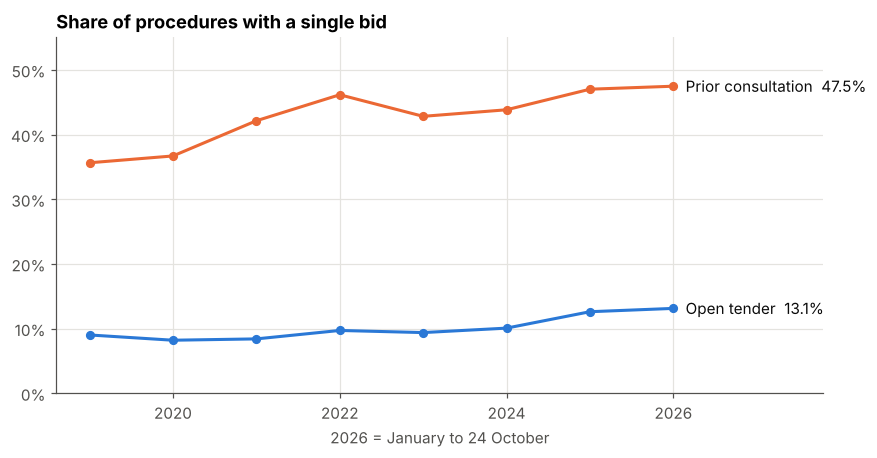

In [7]:
fig, ax = plt.subplots()
for group, color in zip(COMPETITIVE, [BLUE, ORANGE]):
    s = single_by_year[group]
    ax.plot(s.index, s.values, color=color, lw=2, marker="o", ms=5)
    ax.annotate(f"{group}  {s.iloc[-1]:.1%}", (s.index[-1], s.iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=INK)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_ylim(0, 0.55); ax.set_xlim(2018.6, 2027.8)
ax.set_title("Share of procedures with a single bid")
ax.set_xlabel("2026 = January to 24 October"); ax.set_ylabel("")
plt.show()

In [8]:
# Which categories get the fewest bids? Open tenders only, categories with at least 1,000 contracts
ot = comp[comp["procedure_group"] == "Open tender"]
by_cpv = (ot.groupby("cpv_short_name")
            .agg(open_tenders=("idcontrato", "size"), single_bid_share=("bidders", lambda b: b.eq(1).mean()),
                 median_bidders=("bidders", "median"))
            .query("open_tenders >= 1000")
            .sort_values("single_bid_share", ascending=False))
by_cpv.head(8).style.format({"single_bid_share": "{:.1%}", "open_tenders": "{:,}", "median_bidders": "{:.0f}"})

,open_tenders,single_bid_share,median_bidders
cpv_short_name,,,
Software,"3,214",36.8%,2
IT services,"5,016",32.3%,2
Other community services,"1,280",26.4%,3
Repair and maintenance,"5,286",20.2%,3
Postal and telecom services,"1,446",19.4%,2
"Recreation, culture and sport","1,387",17.8%,4
Industrial machinery,"1,791",16.0%,4
Telecom equipment,"2,084",15.7%,4


## 3. Signed price against base price, by number of bidders

The base price is the maximum the buyer is willing to pay, set before bids arrive. The ratio
*signed price / base price* is the share of that ceiling the buyer ends up paying: 1.00 means it paid the
full ceiling, 0.80 means a 20% discount.

Same rules as the dbt mart [`mart_price_vs_base`](../models/marts/mart_price_vs_base.sql): only procedures with a
single contract (a multi-lot procedure publishes one base price for all its lots), both prices above zero, and
ratios between 0.2 and 5 (outside that range the base price is almost always mistyped).

In [9]:
contracts_per_procedure = df.groupby("idprocedimento")["idcontrato"].transform("size")
df["price_ratio"] = np.where((contracts_per_procedure == 1) & (df["base_price"] > 0) & (df["value"] > 0),
                             df["value"] / df["base_price"], np.nan)

sample = df[df["procedure_group"].isin(COMPETITIVE) & (df["bidders"] > 0)
            & df["price_ratio"].between(0.2, 5)].copy()
sample["bidders_capped"] = sample["bidders"].clip(upper=10).astype(int)

ratio_table = sample.pivot_table(index="bidders_capped", columns="procedure_group",
                                 values="price_ratio", aggfunc="median")
counts = sample.pivot_table(index="bidders_capped", columns="procedure_group",
                            values="price_ratio", aggfunc="size")
print(f"{len(sample):,} contracts in the sample")
ratio_table.join(counts, rsuffix=" (contracts)").rename(index={10: "10+"})

272,342 contracts in the sample


procedure_group,Open tender,Prior consultation,Open tender (contracts),Prior consultation (contracts)
bidders_capped,,,,
1,0.993,0.999,14843,100183
2,0.962,0.969,14017,48316
3,0.931,0.974,12116,35931
4,0.919,0.891,9692,5891
5,0.895,0.886,7237,2060
6,0.884,0.853,5415,599
7,0.867,0.855,3964,264
8,0.856,0.840,3012,127
9,0.844,0.820,2246,60


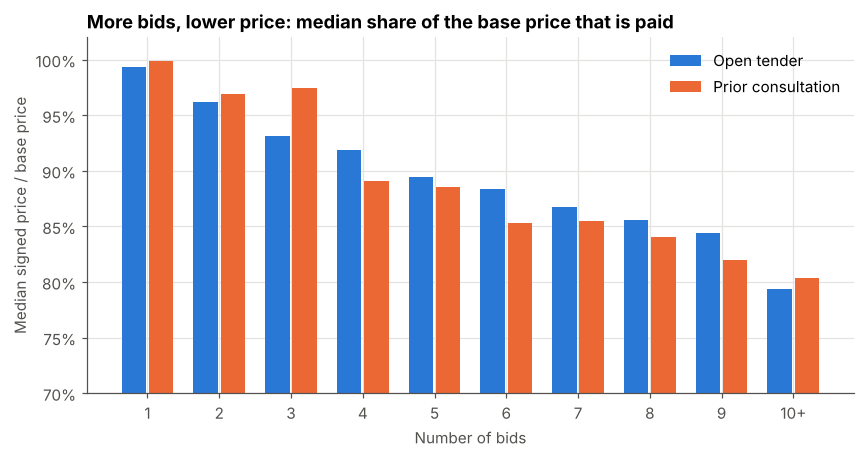

In [10]:
fig, ax = plt.subplots()
x = ratio_table.index.values
w = 0.38
for i, (group, color) in enumerate(zip(COMPETITIVE, [BLUE, ORANGE])):
    ax.bar(x + (i - 0.5) * w, ratio_table[group], width=w - 0.04, color=color, label=group)
ax.set_ylim(0.7, 1.02)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xticks(x, [str(v) if v < 10 else "10+" for v in x])
ax.set_xlabel("Number of bids"); ax.set_ylabel("Median signed price / base price")
ax.set_title("More bids, lower price: median share of the base price that is paid")
ax.legend(frameon=False, loc="upper right")
plt.show()

The fall is steady: every extra bid lowers the median price. But the comparison above mixes very different
contracts. Road works get more bidders than hospital software, and large contracts attract more bidders than
small ones. The regression below holds those differences constant.

## 4. Regression: the price effect of more bidders, other things equal

$$\log\left(\frac{\text{signed price}}{\text{base price}}\right) = \beta \cdot \log(\text{bidders}) + \gamma \cdot \log(\text{base price})
+ \text{procedure} + \text{CPV division} + \text{year} + \text{contract type} + \varepsilon$$

With both sides in logs, $2^{\beta} - 1$ is the change in price when the number of bidders doubles.
Standard errors are robust to heteroscedasticity (HC1).

In [11]:
sample["log_ratio"] = np.log(sample["price_ratio"])
sample["log_bidders"] = np.log(sample["bidders"])
sample["log_base"] = np.log(sample["base_price"])

FE = "C(procedure_group) + C(cpv_division) + C(year) + C(contract_type)"
model = smf.ols(f"log_ratio ~ log_bidders + log_base + {FE}", data=sample).fit(cov_type="HC1")

beta, se = model.params["log_bidders"], model.bse["log_bidders"]
print(f"beta = {beta:.4f} (s.e. {se:.4f}), n = {int(model.nobs):,}, R² = {model.rsquared:.3f}")
print(f"Doubling the number of bidders: {2 ** beta - 1:+.1%} on the price "
      f"(95% CI {2 ** (beta - 1.96 * se) - 1:+.1%} to {2 ** (beta + 1.96 * se) - 1:+.1%})")

beta = -0.0842 (s.e. 0.0007), n = 272,342, R² = 0.132
Doubling the number of bidders: -5.7% on the price (95% CI -5.8% to -5.6%)


In [12]:
# Same model with one dummy per bid count (1 bid is the reference), to see the shape without assuming a log curve
sample["bids"] = sample["bidders"].clip(upper=6).astype(int).astype(str).replace("6", "6+")
dummies = smf.ols(f"log_ratio ~ C(bids) + log_base + {FE}", data=sample).fit(cov_type="HC1")

effects = pd.DataFrame({
    "price_vs_single_bid": np.exp(dummies.params.filter(like="C(bids)")) - 1,
    "ci_low": np.exp(dummies.conf_int().filter(like="C(bids)", axis=0)[0]) - 1,
    "ci_high": np.exp(dummies.conf_int().filter(like="C(bids)", axis=0)[1]) - 1,
})
effects.index = [i.split("T.")[1].rstrip("]") + " bids" for i in effects.index]
effects.style.format("{:+.1%}")

,price_vs_single_bid,ci_low,ci_high
2 bids,-5.4%,-5.5%,-5.2%
3 bids,-6.5%,-6.7%,-6.4%
4 bids,-11.2%,-11.6%,-10.9%
5 bids,-12.4%,-12.8%,-12.0%
6+ bids,-17.5%,-17.9%,-17.2%


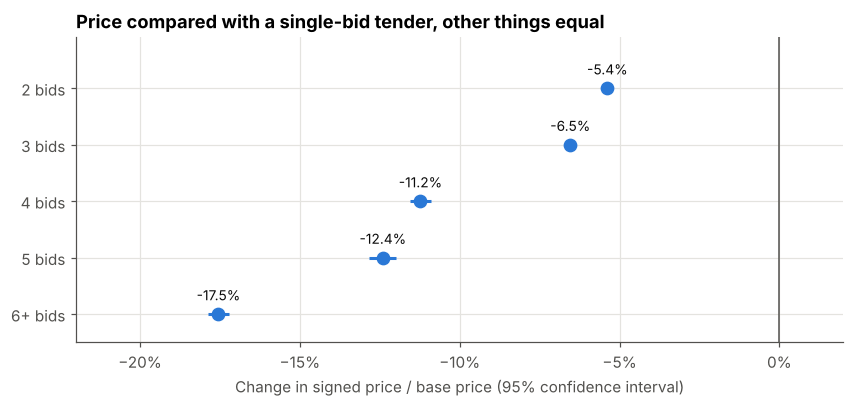

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(effects))
ax.errorbar(effects["price_vs_single_bid"], y,
            xerr=[effects["price_vs_single_bid"] - effects["ci_low"], effects["ci_high"] - effects["price_vs_single_bid"]],
            fmt="o", color=BLUE, ms=8, capsize=0, lw=2)
for yi, v in zip(y, effects["price_vs_single_bid"]):
    ax.annotate(f"{v:+.1%}", (v, yi), xytext=(0, 9), textcoords="offset points", ha="center", color=INK, fontsize=9)
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(y, effects.index); ax.set_ylim(len(effects) - 0.5, -0.9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlim(-0.22, 0.02)
ax.set_title("Price compared with a single-bid tender, other things equal")
ax.set_xlabel("Change in signed price / base price (95% confidence interval)")
plt.show()

## 5. What it is worth, roughly

An illustration, not a saving estimate: if the single-bid open tenders had priced like comparable tenders with
two bids, how much lower would their signed value have been?

In [14]:
two_bids = np.exp(dummies.params["C(bids)[T.2]"]) - 1
single_ot = sample[(sample["procedure_group"] == "Open tender") & (sample["bidders"] == 1)]
print(f"Single-bid open tenders in the sample: {len(single_ot):,} contracts, "
      f"€{single_ot['value'].sum() / 1e9:,.2f}bn signed")
print(f"At the two-bid price ({two_bids:+.1%}): about €{-two_bids * single_ot['value'].sum() / 1e6:,.0f}m lower")

Single-bid open tenders in the sample: 14,843 contracts, €5.80bn signed
At the two-bid price (-5.4%): about €312m lower


## What this does not show

* **Not causal.** Tenders that attract one bid may be different in ways the data do not record (a very specific
  specification, a remote location, a short deadline). Part of the gap may come from those differences, so the
  €-figure above is an upper-bound illustration, not money that was lost.
* **Base prices are set by the buyer.** A buyer that sets a generous base price will see bigger "discounts".
  The CPV, year and size controls absorb part of this, not all of it.
* **Bidders are as reported.** The count comes from the `concorrentes` field; it is missing for most direct awards
  and the notebook leaves those out.
* **The sample** is single-contract procedures with a plausible base price (counted in the cell below), so
  multi-lot tenders are left out.

Next steps that would sharpen this: buyer fixed effects (does the *same* buyer pay less when more firms bid?),
and the announcements dataset, to measure how long each tender was open.

In [15]:
print(f"Sample: {len(sample):,} of {len(comp):,} open tenders and prior consultations with a reported bid count "
      f"({len(sample) / len(comp):.0%})")

Sample: 272,342 of 411,701 open tenders and prior consultations with a reported bid count (66%)
